# Food-101 Image Classification: Fine-Tuning ResNet18
Part 2 of 2. Progressive unfreezing and hyperparameter tuning of the best backbone from Part 1.

Three experiments were carried out:
1. Unfreeze only the last block (layer4)
2. Unfreeze deeper layers (layer3 and layer4)
3. Hyperparameter tuning on experiment-2

The goal is to analyze the effect of fine-tuning different layers on the performance.



---

#**IMPORTING LIBRARIES**
# Importing Libraries

The model is trained using PyTorch and visualisations are done using MatPlotLib and Seaborn.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

import tarfile, os
from collections import Counter



---

#**CONFIGURATION OF DEVICE**

If a GPU is available, we use it to speed up training. Otherwise the computation is done on the CPU.

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


#**DOWNLOADING AND EXTRACTING THE DATASET**

- In Colab, the dataset is downloaded via wget and extracted.
- After this, we deleted the compressed file to save storage.

In [3]:
!wget http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz

--2026-04-24 20:22:59--  http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz [following]
--2026-04-24 20:22:59--  https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4996278331 (4.7G) [application/x-gzip]
Saving to: ‘food-101.tar.gz’

food-101.tar.gz     100%[===================>]   4.65G  31.3MB/s    in 2m 37s  

2026-04-24 20:25:37 (30.4 MB/s) - ‘food-101.tar.gz’ saved [4996278331/4996278331]



In [4]:
with tarfile.open("food-101.tar.gz", "r:gz") as tar:
    tar.extractall("./data")

# We remove the compressed file to save storage
os.remove("food-101.tar.gz")

/tmp/ipykernel_1211/3468607795.py:2: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("./data")




---
#**DATA PREPROCESSING**
The images are resized to 224 * 224 to fit the input size of pre-trained models.

Data augmentation (horizontal flipping) is used to improve model generalisation.

We do normalization using ImageNet statistics as pretrained models were trained on ImageNet.

In [5]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

#**LOADING DATASET**

We will now load the data. The Food101 dataset contains 101 food categories, with 101,000 images. For each class, manually reviewed are provided as follows:

- Training set: 750 images per class
- Test set: 250 images

DataLoaders are used for efficient loading of data in batches during training.

In [6]:
# Load Food101 dataset
train_full = datasets.Food101(root="./data", split="train",
                             transform=train_transform, download=False)

test_dataset = datasets.Food101(root="./data", split="test",
                               transform=test_transform, download=False)

class_names = train_full.classes
print("Total classes:", len(class_names))

Total classes: 101


#**DATA SPLITTING FOR TRAINING AND VALIDATION SET**

In [7]:
train_size = int(0.8 * len(train_full))
val_size = len(train_full) - train_size

train_dataset, val_dataset = random_split(train_full, [train_size, val_size])

#**DATALOADERS**

In [8]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

#**TRAINING FUNCTION**

In [9]:
def train(model, train_loader, val_loader, optimizer, criterion, epochs=5):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct, total = 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = 100 * correct / total

        val_loss, val_acc = evaluate_with_loss(model, val_loader, criterion)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, Train Acc={train_acc:.2f}, Val Acc={val_acc:.2f}")

    return train_losses, val_losses, train_accs, val_accs

#**EVALUATION FUNCTION**

In [10]:
def evaluate_with_loss(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct, total = 0, 0

    with torch.no_grad(): # disable gradients for faster evaluation
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    return total_loss / len(loader), 100 * correct / total

#**RESNET ARCHITECTURE**

In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

We can see from the architecture, all the layers of resnet. In the next step, we will be freezing almost all the layers but will unfreeze layer 3 and layer 4.

#**EXPERIMENT-1 (UNFREEZE LAYER 4)**

In [11]:
# Load pretrained ResNet18
resnet_ft1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers
for p in resnet_ft1.parameters():
    p.requires_grad = False

# Unfreeze layer4
for p in resnet_ft1.layer4.parameters():
    p.requires_grad = True

# Replace classifier
resnet_ft1.fc = nn.Sequential(
    nn.Linear(resnet_ft1.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 101)
)

resnet_ft1 = resnet_ft1.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer1 = optim.Adam(filter(lambda p: p.requires_grad, resnet_ft1.parameters()), lr=1e-4)

ft1_train_loss, ft1_val_loss, ft1_train_acc, ft1_val_acc = train(
    resnet_ft1, train_loader, val_loader, optimizer1, criterion
)

ft1_test = evaluate_with_loss(resnet_ft1, test_loader, criterion)[1]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


Epoch 1: Train Loss=2.3875, Val Loss=1.5227, Train Acc=42.95, Val Acc=60.20
Epoch 2: Train Loss=1.4216, Val Loss=1.3458, Train Acc=62.86, Val Acc=65.16
Epoch 3: Train Loss=1.0778, Val Loss=1.2910, Train Acc=71.13, Val Acc=66.07
Epoch 4: Train Loss=0.8248, Val Loss=1.3215, Train Acc=77.47, Val Acc=66.40
Epoch 5: Train Loss=0.6292, Val Loss=1.4178, Train Acc=82.21, Val Acc=65.74


#**EXPERIMENT-2 (UNFREEZE LAYER 3 AND 4)**

In [12]:
# Load pretrained ResNet18
resnet_ft2 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers
for p in resnet_ft2.parameters():
    p.requires_grad = False

# Unfreeze deeper layers
for p in resnet_ft2.layer3.parameters():
    p.requires_grad = True

for p in resnet_ft2.layer4.parameters():
    p.requires_grad = True

resnet_ft2.fc = nn.Sequential(
    nn.Linear(resnet_ft2.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 101)
)

resnet_ft2 = resnet_ft2.to(device)

optimizer2 = optim.Adam(filter(lambda p: p.requires_grad, resnet_ft2.parameters()), lr=1e-4)

ft2_train_loss, ft2_val_loss, ft2_train_acc, ft2_val_acc = train(
    resnet_ft2, train_loader, val_loader, optimizer2, criterion
)

ft2_test = evaluate_with_loss(resnet_ft2, test_loader, criterion)[1]

Epoch 1: Train Loss=2.2768, Val Loss=1.4475, Train Acc=45.43, Val Acc=62.68
Epoch 2: Train Loss=1.3171, Val Loss=1.2535, Train Acc=65.49, Val Acc=67.21
Epoch 3: Train Loss=0.9884, Val Loss=1.2482, Train Acc=73.52, Val Acc=67.86
Epoch 4: Train Loss=0.7543, Val Loss=1.2144, Train Acc=79.22, Val Acc=69.15
Epoch 5: Train Loss=0.5823, Val Loss=1.2861, Train Acc=83.78, Val Acc=68.73


#**EXPERIMENT-3**
#**HYPERPARAMETER TUNING**

In this experiment, we further improve the best performing model (Experiment 2) by tuning the key hyper-parameters. The first results showed some overfitting, with the training accuracy going up and the validation accuracy dropping off.

The following modifications are made to improve generalisation:
- We used a smaller learning rate to update pretrained weights in a stable way.
- Increased dropout to prevent overfitting.
- Weight decay (regularisation) was introduced

In [22]:
# Load pretrained ResNet
resnet_ft2_improved = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers
for p in resnet_ft2_improved.parameters():
    p.requires_grad = False

# Unfreeze layer3 and layer4
for p in resnet_ft2_improved.layer3.parameters():
    p.requires_grad = True

for p in resnet_ft2_improved.layer4.parameters():
    p.requires_grad = True

# Improved classifier with higher dropout
resnet_ft2_improved.fc = nn.Sequential(
    nn.Linear(resnet_ft2_improved.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.5),   # increased from 0.3 to 0.5
    nn.Linear(512, 101)
)

# Move to device
resnet_ft2_improved = resnet_ft2_improved.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Improved optimizer with lower learning rate and weight decay
optimizer_improved = optim.Adam(
    filter(lambda p: p.requires_grad, resnet_ft2_improved.parameters()),
    lr=5e-5,            # reduced learning rate
    weight_decay=1e-4   # added regularization
)

# Train
imp_train_loss, imp_val_loss, imp_train_acc, imp_val_acc = train(
    resnet_ft2_improved, train_loader, val_loader, optimizer_improved, criterion, epochs=5
)

# Test accuracy
imp_test = evaluate_with_loss(resnet_ft2_improved, test_loader, criterion)[1]


Epoch 1: Train Loss=2.8725, Val Loss=1.6800, Train Acc=34.34, Val Acc=59.01
Epoch 2: Train Loss=1.6450, Val Loss=1.3573, Train Acc=58.45, Val Acc=65.53
Epoch 3: Train Loss=1.2549, Val Loss=1.2436, Train Acc=67.60, Val Acc=67.87
Epoch 4: Train Loss=1.0042, Val Loss=1.1855, Train Acc=73.59, Val Acc=69.68
Epoch 5: Train Loss=0.7978, Val Loss=1.1947, Train Acc=78.48, Val Acc=69.05


#**RESULTS**

We will now see accuracy of both the experiments.

In [13]:
print("Experiment 1 (layer4):", ft1_test)


Experiment 1 (layer4): 71.11287128712871


In [14]:
print("Experiment 2 (layer3+layer4):", ft2_test)

Experiment 2 (layer3+layer4): 74.1980198019802


In [23]:
print("Experiment 3 (hyperparameter tuning):", imp_test)

Experiment 3 (hyperparameter tuning): 75.12871287128714


#**ACCURACY GRAPH**

**FOR EXPERIMENT-1**

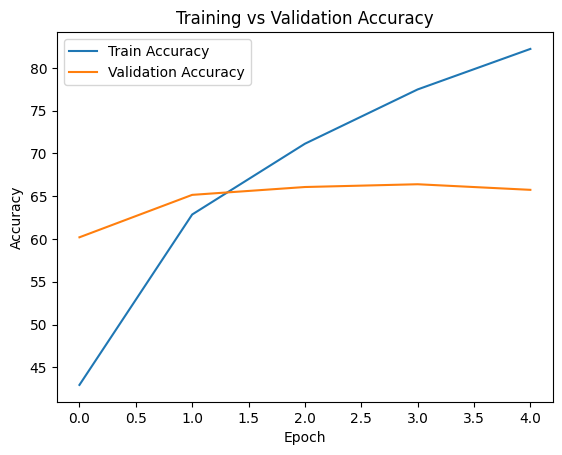

In [17]:
plt.plot(ft1_train_acc, label="Train Accuracy")
plt.plot(ft1_val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

**FOR EXPERIMENT-2**

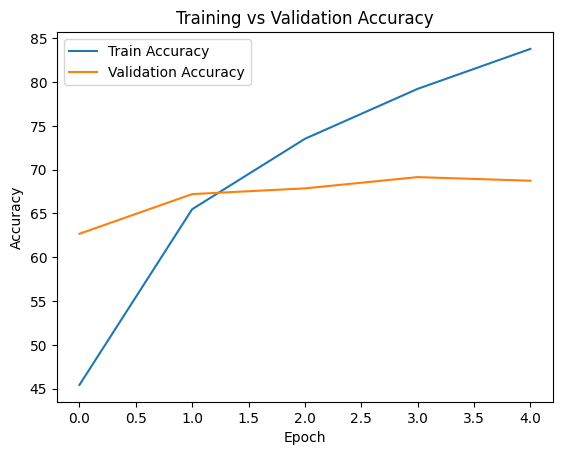

In [15]:
plt.plot(ft2_train_acc, label="Train Accuracy")
plt.plot(ft2_val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

**FOR EXPERIMENT-3**

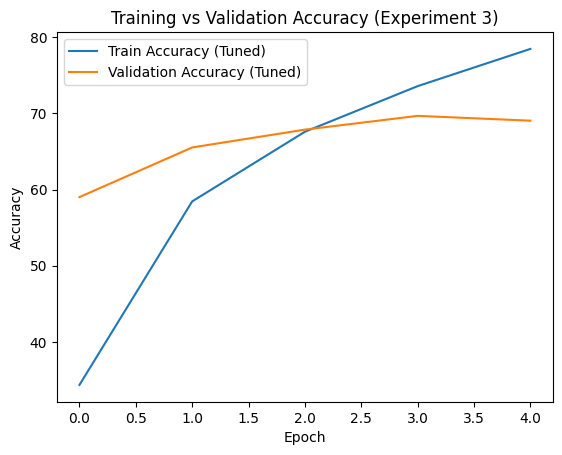

In [24]:
plt.plot(imp_train_acc, label="Train Accuracy (Tuned)")
plt.plot(imp_val_acc, label="Validation Accuracy (Tuned)")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy (Experiment 3)")
plt.legend()
plt.show()

-	The accuracy plot compares the efficiency of various fine-tuning strategies on ResNet18.
-	The validation accuracy in Experiment 1, increases from 60.20% to 65.74%, which is a moderate improvement.
-	In Experiment 2, the validation accuracy increases again to 68.73%. This indicates that the model can learn more features by unfreezing more layers.
-	In Experiment 3, the best generalization performance is achieved with the highest validation accuracy of 69.68%.
-	The results clearly demonstrate that fine-tuning is much better than transfer learning.


#**LOSS GRAPH**

**FOR EXPERIMENT-1**

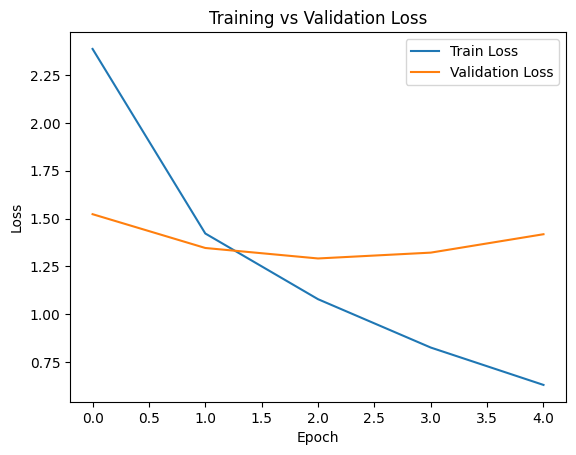

In [18]:
plt.plot(ft1_train_loss, label="Train Loss")
plt.plot(ft1_val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

**FOR EXPERIMENT-2**

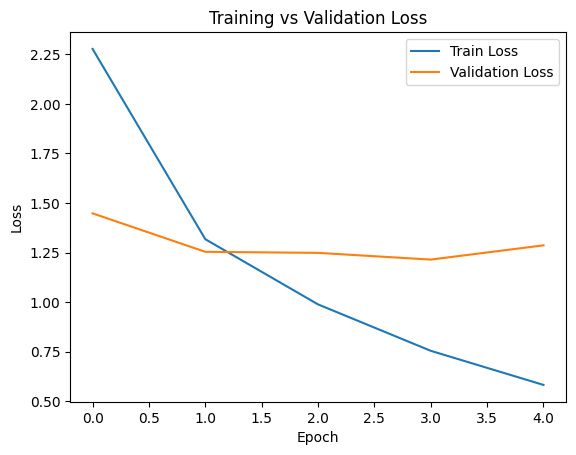

In [16]:
plt.plot(ft2_train_loss, label="Train Loss")
plt.plot(ft2_val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

**FOR EXPERIMENT-3**

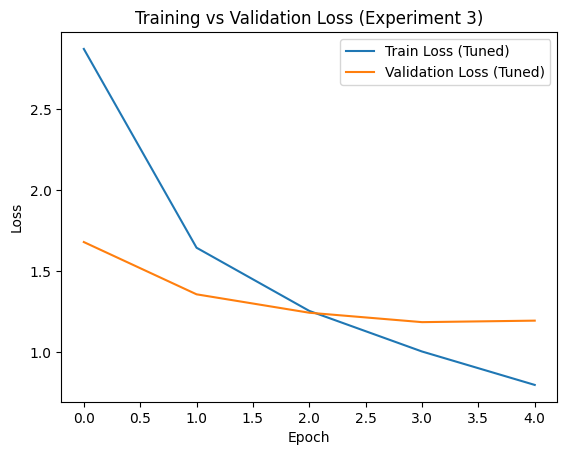

In [25]:
plt.plot(imp_train_loss, label="Train Loss (Tuned)")
plt.plot(imp_val_loss, label="Validation Loss (Tuned)")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss (Experiment 3)")
plt.legend()
plt.show()

-	The loss curves provide information about model optimization in fine-tuning.
-	Experiment 1 shows a slight decrease in validation loss. However, the validation loss is rather high (1.4178) indicating early overfitting.
-	The results of experiment 2 show a better balancing with the validation loss to 1.2861.
-	Experiment 3 has the lowest validation loss of 1.1947 and shows the best generalization.
-	The smaller gap between training and validation loss shows that the model is better regularized and does not overfit.



#**COMPARISON BETWEEN EXPERIMENT-2 AND EXPERIMENT-3**


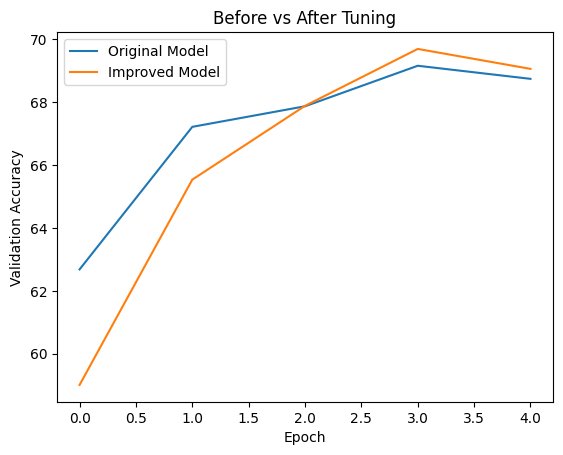

In [26]:
plt.plot(ft2_val_acc, label="Original Model")
plt.plot(imp_val_acc, label="Improved Model")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Before vs After Tuning")
plt.legend()
plt.show()

Tthe comparison indicates that unfreezing more layers enhances feature learning (Experiment 2), but hyperparameter tuning is required to optimize model performance and to achieve better generalization (Experiment 3).

#**CONFUSION MATRIX**

In [19]:
def get_preds(model, loader):
    model.eval()
    preds, labels_list = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, pred = torch.max(outputs, 1)

            preds.extend(pred.cpu().numpy())
            labels_list.extend(labels.numpy())

    return labels_list, preds

**For Experiment-1**






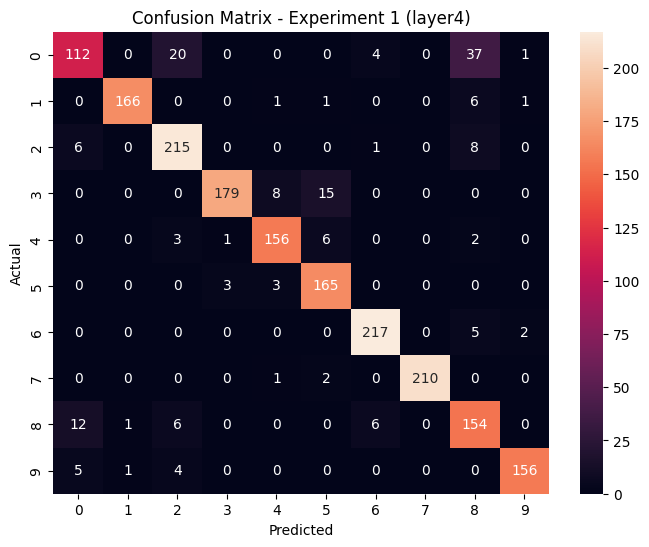

In [20]:
true_ft1, pred_ft1 = get_preds(resnet_ft1, test_loader)

cm_ft1 = confusion_matrix(true_ft1, pred_ft1)

plt.figure(figsize=(8,6))
sns.heatmap(cm_ft1[:10, :10], annot=True, fmt='d')
plt.title("Confusion Matrix - Experiment 1 (layer4)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**For Experiment-2**

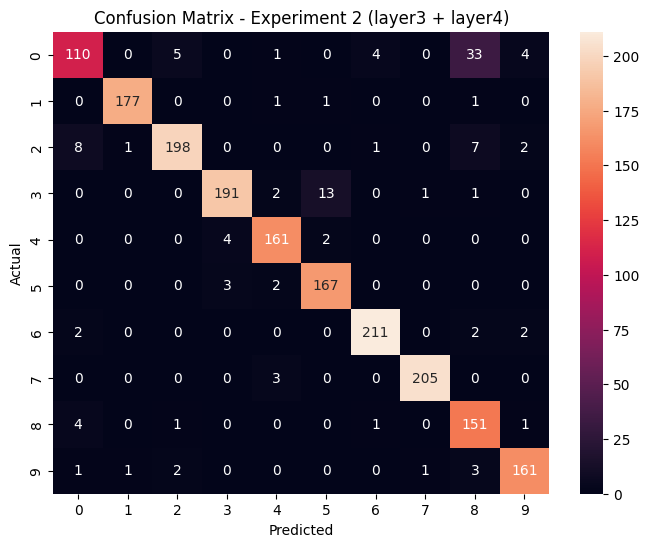

In [21]:
true_ft2, pred_ft2 = get_preds(resnet_ft2, test_loader)

cm_ft2 = confusion_matrix(true_ft2, pred_ft2)

plt.figure(figsize=(8,6))
sns.heatmap(cm_ft2[:10, :10], annot=True, fmt='d')
plt.title("Confusion Matrix - Experiment 2 (layer3 + layer4)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**For Experiment-3**

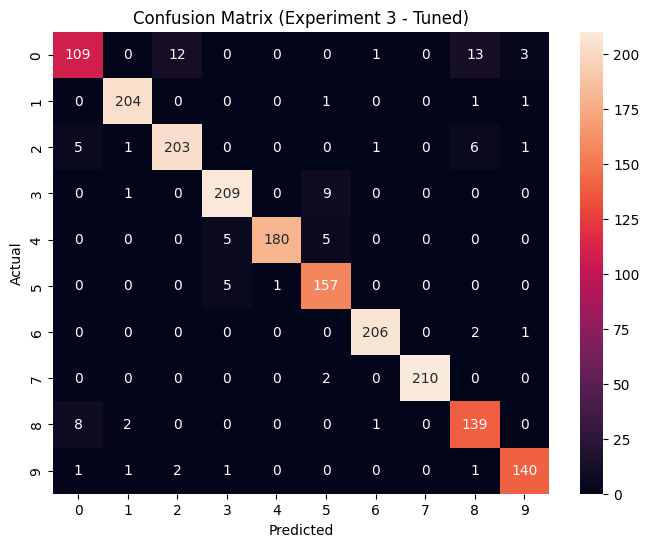

In [27]:
true_ft3, pred_ft3 = get_preds(resnet_ft2_improved, test_loader)

cm_ft3 = confusion_matrix(true_ft3, pred_ft3)

plt.figure(figsize=(8,6))
sns.heatmap(cm_ft3[:10, :10], annot=True, fmt='d')
plt.title("Confusion Matrix (Experiment 3 - Tuned)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

-	The confusion matrix of the fine-tuned model has a more diagonal pattern than the transfer learning model which indicates higher classification accuracy.
-	This reduces misclassifications and the model can better discriminate visually similar classes.
- This confirms that fine-tuning enhances the model to learn more discriminative and dataset-specific features.
-	This result is consistent with theoretical expectations that deeper architectures and fine-tuning enhance feature learning and classification performance.
-	Experiment-3 gives more accurate classification.
